# Per-Capita Crime Rates

Offenses per 100,000 residents in LA, San Diego and San Francisco, using Census city populations.

Only the Violent, Property and Vehicle groups are compared, because LA's data covers victim offenses only. Counts come from `comparable_offenses` (2025 onward).

In [1]:
import os
import sqlite3
import ssl
import urllib.request
from pathlib import Path

import certifi
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import StrMethodFormatter

# Run from backend/ so the data/... paths resolve.
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

db = sqlite3.connect("file:data/crime.db?mode=ro", uri=True)
sql = lambda query: pd.read_sql(query, db)

CITIES = ["Los Angeles", "San Diego", "San Francisco"]
GROUPS = ["Violent", "Property", "Vehicle"]
COLORS = {"Los Angeles": "#2a78d6", "San Diego": "#eb6834", "San Francisco": "#1baf7a"}

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "xtick.color": "#52514e", "ytick.color": "#898781", "text.color": "#0b0b0b",
    "font.size": 9, "axes.titlesize": 10, "lines.linewidth": 1.5,
})

## Population

These are Census Bureau city estimates (Vintage 2025, as of July 1 each year). Rates use city populations, not county ones, because each department only polices its own city.

In [2]:
POP_URL = "https://www2.census.gov/programs-surveys/popest/datasets/2020-2025/cities/totals/sub-est2025_6.csv"
pop_file = Path("data/raw/census/sub-est2025_6.csv")
if not pop_file.exists():
    pop_file.parent.mkdir(parents=True, exist_ok=True)
    # certifi's certificates: uv-installed Pythons on macOS don't see the system ones.
    context = ssl.create_default_context(cafile=certifi.where())
    with urllib.request.urlopen(POP_URL, timeout=120, context=context) as response:
        pop_file.write_bytes(response.read())

census = pd.read_csv(pop_file, dtype=str, encoding="latin-1")
places = {"44000": "Los Angeles", "66000": "San Diego", "67000": "San Francisco"}
counties = {"037": "Los Angeles", "073": "San Diego", "075": "San Francisco"}
years = {f"POPESTIMATE{year}": year for year in range(2020, 2026)}

city_rows = census[census.SUMLEV.eq("162") & census.PLACE.isin(places)]
county_rows = census[census.SUMLEV.eq("050") & census.COUNTY.isin(counties)]
population = (city_rows.set_index(city_rows.PLACE.map(places).rename(None))[list(years)]
              .rename(columns=years).astype(int).loc[CITIES])
county_2025 = county_rows.set_index(county_rows.COUNTY.map(counties))["POPESTIMATE2025"].astype(int)
pop_2025 = population[2025]

display(population.style.format("{:,}"))
pd.DataFrame({"city": pop_2025, "county": county_2025, "city share": pop_2025 / county_2025}) \
    .style.format({"city": "{:,}", "county": "{:,}", "city share": "{:.0%}"})

,2020,2021,2022,2023,2024,2025
Los Angeles,"3,896,473","3,831,478","3,833,523","3,848,289","3,872,710","3,869,089"
San Diego,"1,382,566","1,371,244","1,383,847","1,388,747","1,400,232","1,406,106"
San Francisco,"875,139","816,169","813,266","816,926","820,945","826,079"


,city,county,city share
Los Angeles,"3,869,089","9,694,934",40%
San Diego,"1,406,106","3,282,248",43%
San Francisco,"826,079","826,079",100%


## 2025 rates by crime group

city,Los Angeles,San Diego,San Francisco
crime_group,,,
Violent,"59,875","14,452","10,156"
Property,"80,864","23,890","28,502"
Vehicle,"44,030","9,116","10,774"


city,Los Angeles,San Diego,San Francisco
crime_group,,,
Violent,"1,548","1,028","1,229"
Property,"2,090","1,699","3,450"
Vehicle,"1,138",648,"1,304"


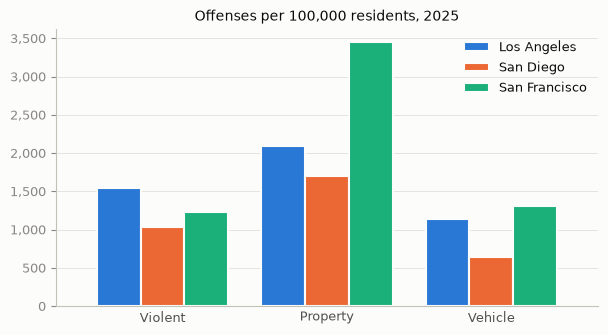

In [3]:
counts = sql("""
    SELECT city, crime_group, COUNT(*) AS offenses, COUNT(DISTINCT case_id) AS cases
    FROM comparable_offenses
    WHERE occurred_date < '2026-01-01' AND crime_group IN ('Violent', 'Property', 'Vehicle')
    GROUP BY city, crime_group
""")
counts["offense_rate"] = counts.offenses / counts.city.map(pop_2025) * 100_000
counts["case_rate"] = counts.cases / counts.city.map(pop_2025) * 100_000

by_group = lambda column: counts.pivot(index="crime_group", columns="city", values=column).loc[GROUPS, CITIES]
rates = by_group("offense_rate")
display(by_group("offenses").style.format("{:,}").set_caption("Offenses"))
display(rates.style.format("{:,.0f}").set_caption("Per 100,000 residents"))

ax = rates.plot.bar(color=[COLORS[city] for city in CITIES], width=0.8, edgecolor="#fcfcfb", linewidth=1.5,
                    rot=0, figsize=(7, 3.6))
ax.set(title="Offenses per 100,000 residents, 2025", xlabel="")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.tick_params(axis="x", length=0)
ax.xaxis.grid(False)
ax.legend(frameon=False);

## 2025 rates by category

Each row is shaded to show which city is highest. SF publishes very few sex offenses, so don't read anything into its number for that row.

In [4]:
by_category = sql("""
    SELECT c.sort_order, o.crime_group, o.crime_category, o.city, COUNT(*) AS offenses
    FROM comparable_offenses AS o JOIN crime_categories AS c USING (crime_category)
    WHERE o.occurred_date < '2026-01-01' AND o.crime_group IN ('Violent', 'Property', 'Vehicle')
    GROUP BY 1, 2, 3, 4
""")
by_category["rate"] = by_category.offenses / by_category.city.map(pop_2025) * 100_000
category_rates = (by_category.pivot_table(index=["sort_order", "crime_group", "crime_category"], columns="city", values="rate")
                  .droplevel("sort_order")[CITIES])
category_rates.style.format("{:,.1f}").background_gradient(cmap="Blues", axis=1)

## Monthly trend

These are offenses per 100,000 residents per month. There is no 2026 population estimate yet, so 2026 uses the 2025 one. The chart stops at the last month all three cities cover in full.

,latest
city,
Los Angeles,2026-10-03
San Diego,2026-10-20
San Francisco,2026-10-19


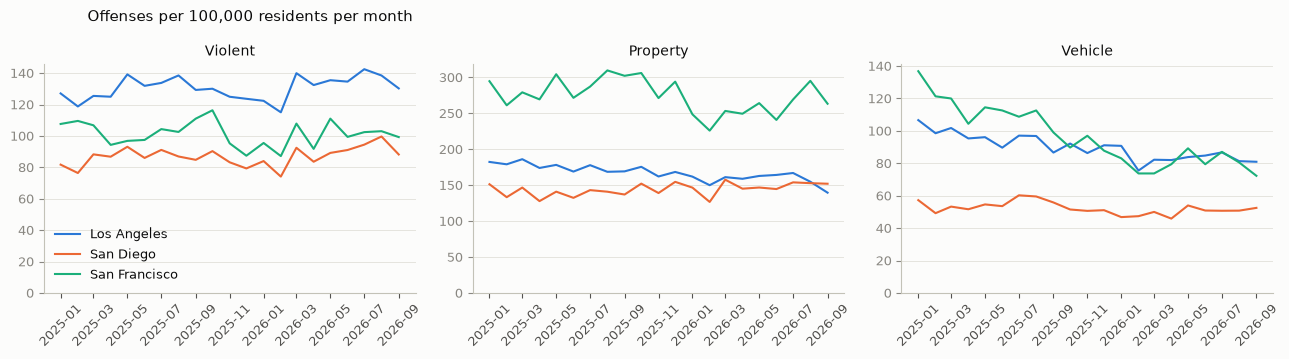

In [5]:
latest = sql("SELECT city, MAX(occurred_date) AS latest FROM offenses GROUP BY city").set_index("city")
end = (pd.Timestamp(latest.latest.min()) + pd.Timedelta(days=1)).to_period("M").start_time
display(latest)

monthly = sql(f"""
    SELECT city, crime_group, substr(occurred_date, 1, 7) AS month, SUM(offense_count) AS offenses
    FROM daily_counts
    WHERE is_crime = 1 AND possible_duplicate = 0
      AND occurred_date >= (SELECT value FROM metadata WHERE key = 'shared_window_start')
      AND occurred_date < '{end:%Y-%m-%d}'
      AND crime_group IN ('Violent', 'Property', 'Vehicle')
    GROUP BY 1, 2, 3
""")
monthly["month"] = pd.to_datetime(monthly.month)
monthly["rate"] = monthly.offenses / monthly.city.map(pop_2025) * 100_000

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, group in zip(axes, GROUPS):
    for city in CITIES:
        series = monthly[(monthly.crime_group == group) & (monthly.city == city)]
        ax.plot(series.month, series.rate, color=COLORS[city], label=city)
    ax.set(title=group, ylim=(0, None))
    ax.tick_params(axis="x", labelrotation=45)
axes[0].legend(frameon=False)
fig.suptitle("Offenses per 100,000 residents per month", x=0.07, ha="left")
fig.tight_layout()

## Same months, 2025 vs 2026

In [6]:
same_months = monthly[monthly.month.dt.month <= monthly.month.max().month]
change = same_months.assign(year=same_months.month.dt.year) \
    .pivot_table(index=["crime_group", "city"], columns="year", values="offenses", aggfunc="sum")
change = (change[2026] / change[2025] - 1).unstack("city").loc[GROUPS, CITIES]
change.style.format("{:+.1%}").set_caption(f"Change in offenses, Jan–{monthly.month.max():%b}")

city,Los Angeles,San Diego,San Francisco
crime_group,,,
Violent,+1.9%,+2.8%,-3.6%
Property,-10.4%,+5.8%,-10.4%
Vehicle,-13.9%,-9.4%,-30.2%


## Checks

**Offenses vs incidents.** One case can have several offenses. Counting distinct cases instead checks whether the ranking holds.

In [7]:
counts.set_index(["crime_group", "city"])[["offense_rate", "case_rate"]].unstack("city").loc[GROUPS] \
    .style.format("{:,.0f}")

**San Diego ZIPs.** The ZIPs that rarely appear include neighboring cities (Chula Vista, National City, El Cajon). Their share of rows is an upper bound on how much crime outside the city inflates SD's count.

In [8]:
sd_zips = sql("""
    SELECT zip, COUNT(*) AS offenses
    FROM comparable_offenses
    WHERE city = 'San Diego' AND occurred_date < '2026-01-01' AND zip IS NOT NULL
      AND crime_group IN ('Violent', 'Property', 'Vehicle')
    GROUP BY zip
""")
rare = sd_zips.offenses < 200
print(f"{rare.sum()} of {len(sd_zips)} ZIPs have under 200 offenses; "
      f"together {sd_zips.offenses[rare].sum() / sd_zips.offenses.sum():.1%} of SD's 2025 rows")

83 of 115 ZIPs have under 200 offenses; together 1.1% of SD's 2025 rows


## Findings

From the run on 2026-10-21. Rates are per 100,000 residents in 2025.

- **Per resident, the picture differs from the raw counts.** LA has 3–6× as many offenses as the other cities, but also 2.8–4.7× the population.
  - SF has the highest Property rate (3,450, against 2,090 for LA and 1,699 for SD) and the highest Vehicle rate (1,304).
  - LA has the highest Violent rate (1,548).
  - SD is lowest in all three groups.
- **SF's property lead comes from theft and burglary.** Theft is 1,588 in SF against about 800 in LA and SD. Burglary is 518 in SF against 299 in LA and 151 in SD.
- **LA's violent lead comes from assaults.**
  - Homicide is 8.6 in LA, 4.4 in SF and 3.0 in SD.
  - SF's robbery rate (208) is slightly above LA's (187).
- **2026 vs 2025 (Jan–Sep):**
  - Vehicle crime is down in all three cities, by 30% in SF.
  - Property crime is down 10% in LA and SF but up 6% in SD.
  - Violent crime is roughly flat.
- **Checks passed:**
  - The ranking is the same when counting distinct cases instead of offenses.
  - Rows in rare SD ZIPs are at most 1.1% of SD's total.
- **County populations would be wrong.** LA and SD are only 40–43% of their counties, so county denominators would cut their rates by more than half.

Caveats:
- These are offense counts, not FBI incident-based crime rates, so they run higher than published figures.
- LA's most recent month may still be filling in.
- SF's sex offense numbers are unreliable.